In [3]:
import pandas as pd
import numpy as np

# فائل کا پاتھ (اسپیس کے ساتھ)
file_path = "/Sale Report.csv"

try:
    df = pd.read_csv(file_path, encoding="utf-8")
except Exception:
    try:
        df = pd.read_csv(file_path, encoding="latin1")
    except Exception:
        # اگر فائل /content فولڈر کے اندر ہو
        df = pd.read_csv("/content/Sale Report.csv", encoding="latin1")

# پہلے 5 ریکارڈز اور کالمز دیکھنا
print("Columns in Dataset:", df.columns.tolist())
df.head()

Columns in Dataset: ['index', 'SKU Code', 'Design No.', 'Stock', 'Category', 'Size', 'Color']


,index,SKU Code,Design No.,Stock,Category,Size,Color
0,0,AN201-RED-L,AN201,5.0,AN : LEGGINGS,L,Red
1,1,AN201-RED-M,AN201,5.0,AN : LEGGINGS,M,Red
2,2,AN201-RED-S,AN201,3.0,AN : LEGGINGS,S,Red
3,3,AN201-RED-XL,AN201,6.0,AN : LEGGINGS,XL,Red
4,4,AN201-RED-XXL,AN201,3.0,AN : LEGGINGS,XXL,Red


In [4]:
# Missing values aur duplicates check karna
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.info()

Missing values:
 index          0
SKU Code      83
Design No.    36
Stock         36
Category      45
Size          36
Color         45
dtype: int64

Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9271 entries, 0 to 9270
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   index       9271 non-null   int64  
 1   SKU Code    9188 non-null   object 
 2   Design No.  9235 non-null   object 
 3   Stock       9235 non-null   float64
 4   Category    9226 non-null   object 
 5   Size        9235 non-null   object 
 6   Color       9226 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 507.1+ KB


In [5]:
# Missing values ko handle karna (agar text columns khali hon to 'Unknown' kar dega)
df.fillna({'Stock': 0, 'Category': 'Unknown', 'Size': 'Unknown', 'Color': 'Unknown'}, inplace=True)

# Duplicates remove karna agar koi hon
df.drop_duplicates(inplace=True)

# Confirm karein ke clean ho gaya
print("Remaining Missing Values:\n", df.isnull().sum())
print("\nCleaned Dataset Shape:", df.shape)

Remaining Missing Values:
 index          0
SKU Code      83
Design No.    36
Stock          0
Category       0
Size           0
Color          0
dtype: int64

Cleaned Dataset Shape: (9271, 7)


In [6]:
# Bachi hui missing product codes wali rows ko drop karein
df.dropna(subset=['SKU Code', 'Design No.'], inplace=True)

# Basic business metrics calculate karein
print("Total Unique Products (SKUs):", df['SKU Code'].nunique())
print("Total Unique Designs:", df['Design No.'].nunique())
print("Total Categories:", df['Category'].nunique())
print("Total Stock Available:", int(df['Stock'].sum()))
print("Final Cleaned Rows:", len(df))

Total Unique Products (SKUs): 9170
Total Unique Designs: 1591
Total Categories: 21
Total Stock Available: 242370
Final Cleaned Rows: 9188


/tmp/ipykernel_896/1466173240.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, ax=axes[0], palette='Blues_r')
/tmp/ipykernel_896/1466173240.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_colors.values, y=top_colors.index, ax=axes[1], palette='crest')


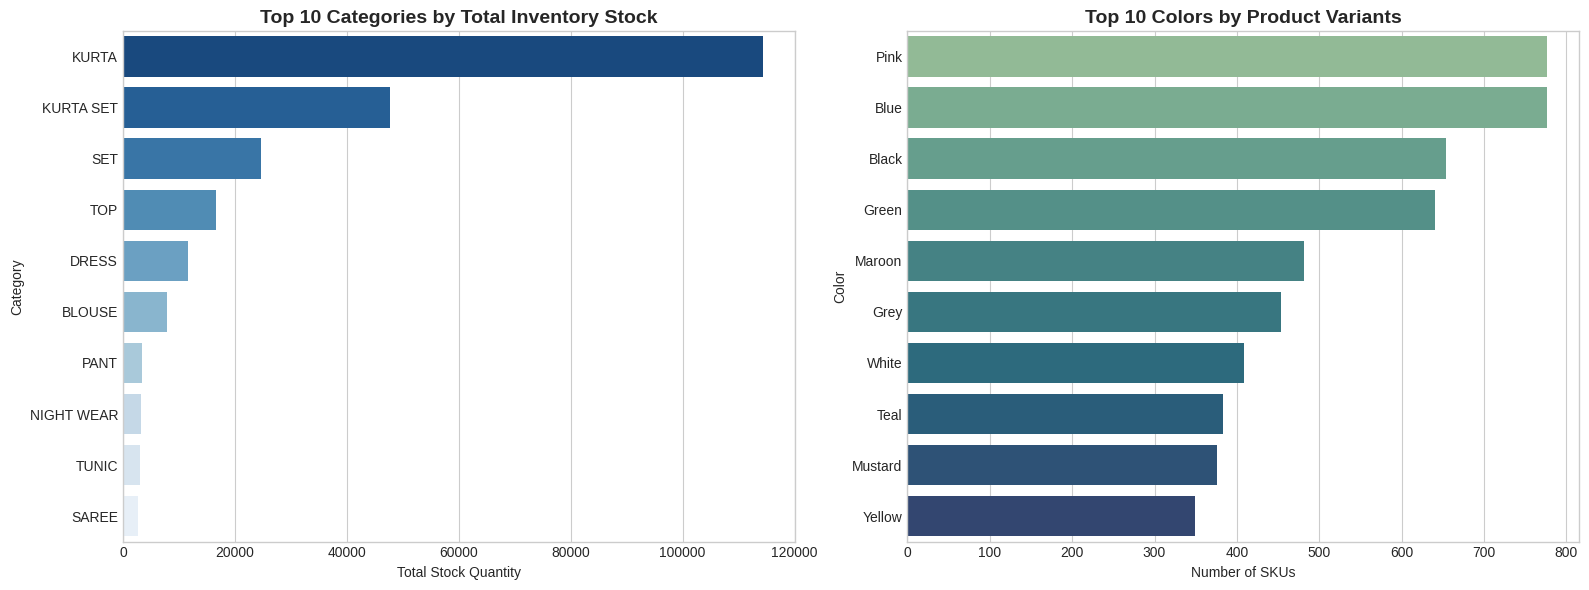

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visual settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Top 10 Product Categories by Available Stock
top_categories = df.groupby('Category')['Stock'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_categories.values, y=top_categories.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Categories by Total Inventory Stock', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Stock Quantity')
axes[0].set_ylabel('Category')

# Chart 2: Top 10 Colors by Product Count
top_colors = df['Color'].value_counts().head(10)
sns.barplot(x=top_colors.values, y=top_colors.index, ax=axes[1], palette='crest')
axes[1].set_title('Top 10 Colors by Product Variants', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of SKUs')
axes[1].set_ylabel('Color')

plt.tight_layout()
plt.show()

/tmp/ipykernel_896/2118069630.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=valid_sizes, x='Size', order=size_order, palette='viridis')


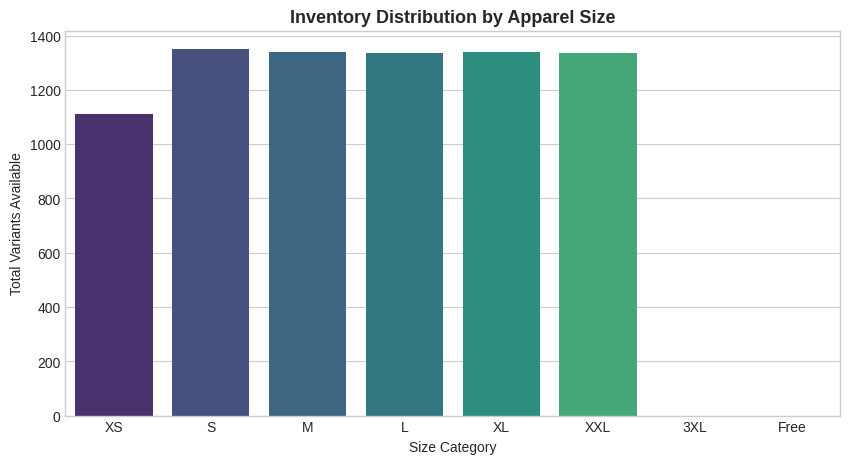

--- Inventory Concentration Insights ---
Top 3 Categories hold: 77.01% of total stock.
Top Category by Stock: KURTA (114333.0 units)


In [8]:
# 1. Size distribution count
plt.figure(figsize=(10, 5))
size_order = ['XS', 'S', 'M', 'L', 'XL', 'XXL', '3XL', 'Free']
valid_sizes = df[df['Size'].isin(size_order)]

sns.countplot(data=valid_sizes, x='Size', order=size_order, palette='viridis')
plt.title('Inventory Distribution by Apparel Size', fontsize=13, fontweight='bold')
plt.xlabel('Size Category')
plt.ylabel('Total Variants Available')
plt.show()

# 2. Pareto analysis: Top 10% categories kitna stock hold karti hain?
category_stock = df.groupby('Category')['Stock'].sum().sort_values(ascending=False)
cumulative_stock = (category_stock.cumsum() / category_stock.sum()) * 100

print("--- Inventory Concentration Insights ---")
print(f"Top 3 Categories hold: {cumulative_stock.iloc[2]:.2f}% of total stock.")
print("Top Category by Stock:", category_stock.index[0], f"({category_stock.iloc[0]} units)")

In [9]:
import sqlite3

# 1. In-memory SQLite database create karein aur DataFrame ko load karein
conn = sqlite3.connect(':memory:')
df.to_sql('inventory', conn, index=False, if_exists='replace')

# 2. Query 1: Top 5 Categories with highest average stock per SKU
query1 = """
SELECT
    Category,
    COUNT("SKU Code") AS Total_Variants,
    ROUND(AVG(Stock), 2) AS Avg_Stock_Per_Variant,
    SUM(Stock) AS Total_Stock
FROM inventory
GROUP BY Category
ORDER BY Total_Stock DESC
LIMIT 5;
"""
print("--- SQL Query 1: Category Stock Performance ---")
print(pd.read_sql_query(query1, conn))

# 3. Query 2: Identifying Low Stock / Out of Stock Risks (Stock <= 2)
query2 = """
SELECT
    Category,
    COUNT(CASE WHEN Stock = 0 THEN 1 END) AS Out_Of_Stock_SKUs,
    COUNT(CASE WHEN Stock BETWEEN 1 AND 2 THEN 1 END) AS Low_Stock_Alert,
    COUNT("SKU Code") AS Total_SKUs
FROM inventory
GROUP BY Category
HAVING Out_Of_Stock_SKUs > 0 OR Low_Stock_Alert > 0
ORDER BY Low_Stock_Alert DESC
LIMIT 5;
"""
print("\n--- SQL Query 2: Inventory Stockout Risk Alert ---")
print(pd.read_sql_query(query2, conn))

--- SQL Query 1: Category Stock Performance ---
    Category  Total_Variants  Avg_Stock_Per_Variant  Total_Stock
0      KURTA            3704                  30.87     114333.0
1  KURTA SET            1596                  29.88      47682.0
2        SET            1049                  23.49      24643.0
3        TOP             861                  19.29      16608.0
4      DRESS             700                  16.68      11675.0

--- SQL Query 2: Inventory Stockout Risk Alert ---
    Category  Out_Of_Stock_SKUs  Low_Stock_Alert  Total_SKUs
0      KURTA                189              625        3704
1  KURTA SET                114              266        1596
2        TOP                 83              216         861
3      DRESS                 55              179         700
4        SET                 73              136        1049
